# Polynomial Regression Using Gradient Descent with Momentum

In this project, we apply Polynomial Regression to predict car fuel efficiency (MPG) based on vehicle weight using the Auto MPG dataset.

We use a polynomial model of degree 2 to capture the relationship between weight and MPG. The model is trained using Gradient Descent with Momentum to minimize prediction error.

Finally, we evaluate the model using Mean Squared Error (MSE) and R-squared (R²).

In [37]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv


## 1. Polynomial Regression Model

Polynomial Regression extends Linear Regression by adding polynomial features to capture curved relationships between variables.

In this project, we use a polynomial model of degree 2:

$$
\hat{y} = w_0 + w_1x + w_2x^2
$$

Where:
- $x$: Car weight.
- $\hat{y}$: Predicted MPG.
- $w_0, w_1, w_2$: Model weights.

## 2. Dataset Description

The Auto MPG dataset contains information about different cars, including their weight and fuel efficiency.

In this project:
- **Input Feature (X):** Weight
- **Target Variable (y):** MPG (Miles Per Gallon)

The goal is to predict the fuel efficiency of a car based on its weight.

import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')

df.head()

In [38]:
df = pd.read_csv('/kaggle/input/datasets/uciml/autompg-dataset/auto-mpg.csv')

In [39]:
print(df.shape)
print(df.info())

(398, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB
None


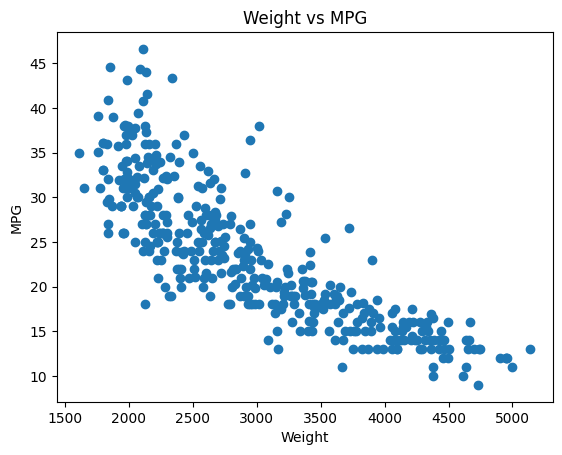

In [40]:
import matplotlib.pyplot as plt

plt.scatter(df['weight'], df['mpg'])
plt.xlabel('Weight')
plt.ylabel('MPG')
plt.title('Weight vs MPG')
plt.show()


In [41]:
X = df[['weight']].values
y = df['mpg'].values

print(X.shape)
print(y.shape)

(398, 1)
(398,)


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(318, 1)
(80, 1)


In [43]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape)
print(X_test_poly.shape)


(318, 3)
(80, 3)


In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train_poly.copy()
X_test_scaled = X_test_poly.copy()

X_train_scaled[:, 1:] = scaler.fit_transform(X_train_poly[:, 1:])
X_test_scaled[:, 1:] = scaler.transform(X_test_poly[:, 1:])

In [45]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(318, 3)
(80, 3)


## 4. Gradient Descent with Momentum

Gradient Descent updates the model weights using the calculated gradient to minimize the Mean Squared Error.

Momentum helps accelerate the optimization process by using information from previous updates.

### Mathematical Formulas

The Gradient:

$$
\nabla J(w)=\frac{2}{n}X^T(Xw-y)
$$

The Momentum Update:

$$
v_t=\beta v_{t-1}+\nabla J(w)
$$

The Weight Update:

$$
w_t=w_{t-1}-\alpha v_t
$$

### Hyperparameters
- Learning Rate = 0.01
- Momentum = 0.9
- Epochs = 1000

We use the full training dataset to calculate the gradient in each epoch.

In [46]:
# Initialize parameters
weights = np.zeros(X_train_scaled.shape[1])
velocity = np.zeros(X_train_scaled.shape[1])

# Hyperparameters
learning_rate = 0.01
momentum = 0.9
epochs = 1000

n = len(y_train)
loss_history = []

# Training
for epoch in range(epochs):

    predictions = X_train_scaled @ weights

    error = predictions - y_train

    gradient = (2 / n) * (X_train_scaled.T @ error)

    velocity = momentum * velocity + gradient

    weights = weights - learning_rate * velocity

    loss = np.mean(error ** 2)
    loss_history.append(loss)

print("Final Training MSE:", loss_history[-1])

Final Training MSE: 18.552780451469374


## 5. Model Evaluation

After training the model, we evaluate its performance using two metrics:

### Mean Squared Error (MSE)

MSE measures the average squared difference between actual and predicted values.

$$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

A lower MSE indicates better prediction accuracy.

### R-squared (R²)

R² measures how well the model explains the variation in the target variable.

A value closer to 1 indicates a better fit.

In [47]:
y_pred = X_test_scaled @ weights

test_mse = np.mean((y_test - y_pred) ** 2)

print("Test MSE:", test_mse)

Test MSE: 13.329991459489989


In [48]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.7520760063382472


## 6. Training Loss Curve

The following plot shows how the training MSE changes over the epochs.

A decreasing curve indicates that the model is learning and reducing its prediction error. When the curve becomes nearly stable, the model has reached convergence.

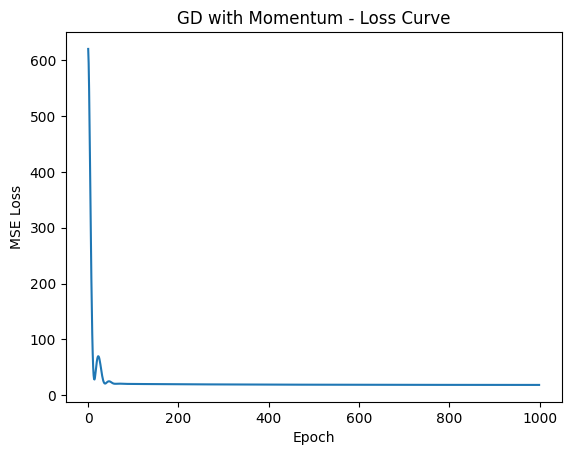

In [49]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("GD with Momentum - Loss Curve")
plt.show()

## 7. Results and Conclusion

The model achieved the following results:

- Training MSE: 18.55
- Test MSE: 13.33
- R² Score: 0.7521

The R² score indicates that the model explains approximately 75.21% of the variation in MPG on the test data.

The results show that Gradient Descent with Momentum successfully reduced the training error and learned a relationship between car weight and fuel efficiency.